In [56]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt


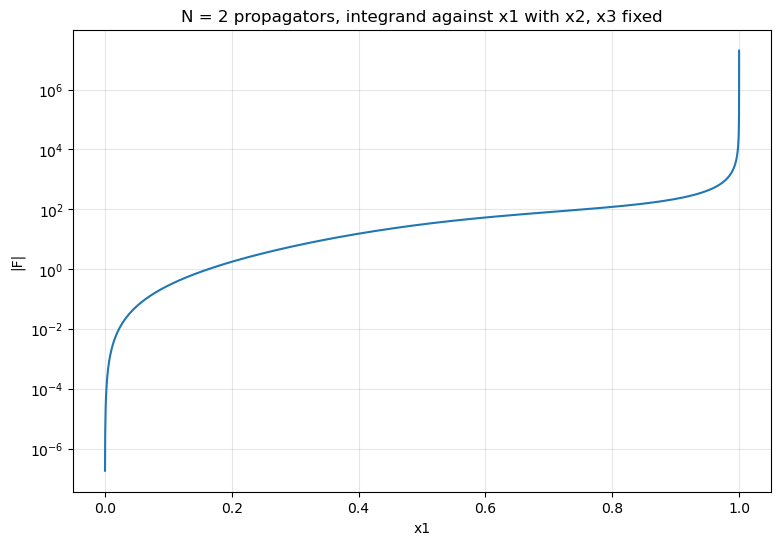

In [58]:



N = 2
EPS = 1e-3           
MASSES = [1.0, 1.0]
P = [(0.0, 0.0, 0.0, 0.0), (0.3, 0.2, 0.2, 0.2)] 
x2, x3 = 0.9, 0.9                       



def poles(x1, x2, x3):
    cos_theta = 2.0 * x2 - 1.0
    sin_theta = 2.0 * np.sqrt(x2 * (1.0 - x2))
    phi = 2.0 * np.pi * x3
    nx = sin_theta * np.cos(phi)
    ny = sin_theta * np.sin(phi)
    nz = cos_theta

    E_plus = []
    E_minus = []
    for j in range(N):
        p0, px, py, pz = P[j]
        p_dot_n = px * nx + py * ny + pz * nz
        p_squared = px**2 + py**2 + pz**2
        root = np.sqrt(x1**2 - 2.0 * x1 * p_dot_n + p_squared + MASSES[j]**2 - 1j * EPS)         
        E_plus.append(p0 + root)
        E_minus.append(p0 - root)
    return E_plus, E_minus

def sum_residues(E_plus, E_minus):
    total = 0.0
    for j in range(N):
        term = 1.0 / (E_plus[j] - E_minus[j])
        for k in range(N):
            if k != j:
                term = term / ((E_plus[j] - E_plus[k]) * (E_plus[j] - E_minus[k]))
        total = total + term
    return total


def integrand(x1, x2, x3):
    xq = x1 / (1.0 - x1)
    E_plus, E_minus = poles(xq, x2, x3)
    S = sum_residues(E_plus, E_minus)

    jacobian = xq**2 * (1.0 + xq) ** 2        
    return -8.0 * np.pi**2 * 1j * jacobian * S



x1_values = np.concatenate([np.linspace(1e-4, 0.99, 3000),
                            1.0 - np.logspace(-2, -6, 3000)])

plt.figure(figsize=(9, 6))
F = integrand(x1_values, x2, x3)
plt.semilogy(x1_values, np.abs(F))

plt.xlabel("x1")
plt.ylabel("|F|")
plt.title(f"N = {N} propagators, integrand against x1 with x2, x3 fixed")
plt.grid(alpha=0.3)
plt.show()